In [1]:
%pip -q install "transformers>=4.44" datasets jiwer wordfreq librosa soundfile accelerate

In [2]:
import io
import re
from pathlib import Path

import librosa
import jiwer
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf
import torch

from datasets import Audio, load_dataset
from transformers import (
    AutoModelForCTC,
    AutoProcessor,
    WhisperForConditionalGeneration,
    WhisperProcessor,
)
from wordfreq import zipf_frequency
from tqdm.auto import tqdm

# Use the GPU if Colab provides one; otherwise this will run on CPU.
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

# Record exact model checkpoints so the comparison is reproducible.
WHISPER_ID = "openai/whisper-small"
WAV2VEC_ID = "facebook/wav2vec2-base-960h"

# Accent labels copied from EDACC's accent-count table.
ACCENTS = [
    "Nigerian English",
    "Kenyan English",
    "Ghanain English",
    "Jamaican English",
    "Indian English",
    "Mainstream US English",
    "Southern British English",
    "Irish English",
]

FOCUS = "Nigerian English"
BASELINE = "Mainstream US English"

N_PER_ACCENT = 200
MIN_REF_WORDS = 3
MAX_DURATION_SEC = 30
SEED = 42

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
})
PAL = sns.color_palette("colorblind")

Device: cpu


In [3]:
# Load the test split and keep audio encoded until we need a clip.
ds = load_dataset("edinburghcstr/edacc", split="test")
ds = ds.cast_column("audio", Audio(decode=False))

# Inspect metadata without decoding the audio files.
meta = ds.remove_columns("audio").to_pandas()
meta["row"] = np.arange(len(meta))

accent_counts = (
    meta.groupby("accent")
    .agg(clips=("row", "size"), speakers=("speaker", "nunique"))
    .sort_values("clips", ascending=False)
)
display(accent_counts)

data/test-00000-of-00010-f0aceb1ca4406ff(…): reconstructing file:   0%|          |  0.00B /  471MB            

data/test-00000-of-00010-f0aceb1ca4406ff(…): downloading bytes:           |  0.00B            

data/test-00001-of-00010-856b016d9d438ff(…): reconstructing file:   0%|          |  0.00B /  274MB            

data/test-00001-of-00010-856b016d9d438ff(…): downloading bytes:           |  0.00B            

data/test-00002-of-00010-2b021baedb4deb8(…): reconstructing file:   0%|          |  0.00B /  333MB            

data/test-00002-of-00010-2b021baedb4deb8(…): downloading bytes:           |  0.00B            

... (13 outputs left out)

data/test-00009-of-00010-648ce5002d12449(…): downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/9848 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/9289 [00:00<?, ? examples/s]

,clips,speakers
accent,,
Nigerian English,1356,5
Kenyan English,1157,2
Mainstream US English,887,9
Spanish,879,5
Indian English,631,3
Vietnamese,583,6
Lithuanian,578,2
Jamaican English,458,4
Ghanain English,357,1


In [4]:
def audio_duration_s(audio_record):
    """Read audio metadata to get duration without decoding the waveform."""
    source = (
        io.BytesIO(audio_record["bytes"])
        if audio_record.get("bytes") is not None
        else audio_record["path"]
    )
    return sf.info(source).duration


meta["ref_words"] = meta["text"].fillna("").str.split().str.len()

eligible = meta[
    meta["accent"].isin(ACCENTS)
    & (meta["ref_words"] >= MIN_REF_WORDS)
].copy()

# Sample clips within each accent. This balances clip counts, not speakers.
parts = []
for accent, group in eligible.groupby("accent", sort=False):
    parts.append(
        group.sample(
            n=min(len(group), N_PER_ACCENT),
            random_state=SEED,
        )
    )

sample = pd.concat(parts, ignore_index=True)

# Filter to the same duration range for both model runs.
sample["duration_s"] = sample["row"].map(
    lambda row_id: audio_duration_s(ds[int(row_id)]["audio"])
)
sample = sample[sample["duration_s"] <= MAX_DURATION_SEC].reset_index(drop=True)

sample_summary = (
    sample.groupby("accent")
    .agg(
        clips=("row", "size"),
        speakers=("speaker", "nunique"),
        median_clips_per_speaker=(
            "speaker",
            lambda values: values.value_counts().median(),
        ),
    )
    .reindex(ACCENTS)
)
display(sample_summary)
print(f"Total clips selected: {len(sample)}")

,clips,speakers,median_clips_per_speaker
accent,,,
Nigerian English,190,5,20.0
Kenyan English,196,2,98.0
Ghanain English,131,1,131.0
Jamaican English,194,4,47.0
Indian English,198,3,86.0
Mainstream US English,179,9,24.0
Southern British English,153,2,76.5
Irish English,181,3,67.0


Total clips selected: 1422


In [5]:
# Load models and their matching processors.
whisper_processor = WhisperProcessor.from_pretrained(WHISPER_ID)
whisper_model = WhisperForConditionalGeneration.from_pretrained(
    WHISPER_ID
).to(DEVICE)
whisper_model.eval()

wav2vec_processor = AutoProcessor.from_pretrained(WAV2VEC_ID)
wav2vec_model = AutoModelForCTC.from_pretrained(WAV2VEC_ID).to(DEVICE)
wav2vec_model.eval()


def load_audio(audio_record):
    """Read an EDACC record and return mono audio sampled at 16 kHz."""
    source = (
        io.BytesIO(audio_record["bytes"])
        if audio_record.get("bytes") is not None
        else audio_record["path"]
    )
    audio, sampling_rate = sf.read(source, dtype="float32")

    if audio.ndim > 1:
        audio = audio.mean(axis=1)

    if sampling_rate != 16_000:
        audio = librosa.resample(
            audio,
            orig_sr=sampling_rate,
            target_sr=16_000,
        )

    return audio


def transcribe_whisper(audio_16k):
    """Return Whisper transcript and mean generated-token log-probability."""
    inputs = whisper_processor(
        audio_16k,
        sampling_rate=16_000,
        return_tensors="pt",
    )
    inputs = {key: value.to(DEVICE) for key, value in inputs.items()}

    with torch.inference_mode():
        output = whisper_model.generate(
            input_features=inputs["input_features"],
            max_new_tokens=200,
            do_sample=False,
            language="en",
            task="transcribe",
            return_dict_in_generate=True,
            output_scores=True,
        )

    if output.scores is None or len(output.scores) == 0:
        raise RuntimeError(
            "Whisper did not return token scores. Stop before confidence analysis."
        )

    transcript = whisper_processor.batch_decode(
        output.sequences,
        skip_special_tokens=True,
    )[0].strip()

    token_logprobs = whisper_model.compute_transition_scores(
        output.sequences,
        output.scores,
        beam_indices=getattr(output, "beam_indices", None),
        normalize_logits=True,
    )[0]

    generated_ids = output.sequences[0, -len(token_logprobs):]
    special_ids = set(whisper_processor.tokenizer.all_special_ids)
    keep = torch.tensor(
        [token_id.item() not in special_ids for token_id in generated_ids],
        device=token_logprobs.device,
    )

    mean_logprob = (
        token_logprobs[keep].mean().item()
        if keep.any()
        else float("nan")
    )
    return transcript, mean_logprob


def mean_logprob_for_ctc_path(logits, blank_id):
    """Approximate mean log-probability over greedy CTC output tokens."""
    frame_logprobs = torch.log_softmax(logits[0], dim=-1)
    frame_ids = logits[0].argmax(dim=-1).tolist()

    token_scores = []
    current_id = None
    current_frame_scores = []

    for frame_index, token_id in enumerate(frame_ids):
        if token_id == blank_id:
            if current_frame_scores:
                token_scores.append(torch.stack(current_frame_scores).mean())
                current_frame_scores = []
            current_id = None
        elif token_id == current_id:
            current_frame_scores.append(frame_logprobs[frame_index, token_id])
        else:
            if current_frame_scores:
                token_scores.append(torch.stack(current_frame_scores).mean())
            current_id = token_id
            current_frame_scores = [frame_logprobs[frame_index, token_id]]

    if current_frame_scores:
        token_scores.append(torch.stack(current_frame_scores).mean())

    return (
        torch.stack(token_scores).mean().item()
        if token_scores
        else float("nan")
    )


def transcribe_wav2vec(audio_16k):
    """Return wav2vec transcript and approximate greedy-path confidence."""
    inputs = wav2vec_processor(
        audio_16k,
        sampling_rate=16_000,
        return_tensors="pt",
        padding=True,
    )
    inputs = {key: value.to(DEVICE) for key, value in inputs.items()}

    with torch.inference_mode():
        logits = wav2vec_model(**inputs).logits

    token_ids = torch.argmax(logits, dim=-1)
    transcript = wav2vec_processor.batch_decode(token_ids)[0].strip()
    mean_logprob = mean_logprob_for_ctc_path(
        logits,
        blank_id=wav2vec_model.config.pad_token_id,
    )
    return transcript, mean_logprob

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.97k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/836k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/494k [00:00<?, ?B/s]

... (12 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-base-960h
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [6]:
test_row = sample.iloc[0]
test_audio = load_audio(ds[int(test_row["row"])]["audio"])

whisper_text, whisper_confidence = transcribe_whisper(test_audio)
wav2vec_text, wav2vec_confidence = transcribe_wav2vec(test_audio)

print("Accent:", test_row["accent"])
print("Speaker:", test_row["speaker"])
print("Reference:", test_row["text"])
print()
print("Whisper:", whisper_text)
print("Whisper mean token log-probability:", whisper_confidence)
print()
print("wav2vec 2.0:", wav2vec_text)
print("wav2vec mean token log-probability:", wav2vec_confidence)

[transformers] The following generation flags are not valid and may be ignored: ['output_scores']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress

Accent: Mainstream US English
Speaker: EDACC-C64-A
Reference: RECENTLY RECENTLY YEAH BUT NOW NOT

Whisper: Recently, but not not.
Whisper mean token log-probability: -0.3607240915298462

wav2vec 2.0: RETETEA BUT NOT NA
wav2vec mean token log-probability: -0.3872213363647461


In [7]:
RESULTS_PATH = Path("edacc_two_model_predictions.csv")
SAVE_EVERY = 25

expected_rows = set(sample["row"].astype(int))

if RESULTS_PATH.exists():
    previous = pd.read_csv(RESULTS_PATH)
    previous = previous[previous["row"].astype(int).isin(expected_rows)]
    results = {
        int(record["row"]): record
        for record in previous.to_dict("records")
    }
    print(f"Resuming with {len(results)} saved clips.")
else:
    results = {}


def save_results():
    pd.DataFrame(results.values()).sort_values("row").to_csv(
        RESULTS_PATH,
        index=False,
    )


for _, row in tqdm(sample.iterrows(), total=len(sample), desc="Scoring clips"):
    row_id = int(row["row"])

    # Skip clips already scored by both models.
    if (
        row_id in results
        and pd.notna(results[row_id].get("whisper_text"))
        and pd.notna(results[row_id].get("wav2vec_text"))
    ):
        continue

    audio_16k = load_audio(ds[row_id]["audio"])

    whisper_text, whisper_mean_logprob = transcribe_whisper(audio_16k)
    wav2vec_text, wav2vec_mean_logprob = transcribe_wav2vec(audio_16k)

    results[row_id] = {
        "row": row_id,
        "accent": row["accent"],
        "speaker": row["speaker"],
        "l1": row.get("l1"),
        "gender": row.get("gender"),
        "duration_s": len(audio_16k) / 16_000,
        "reference": row["text"],
        "whisper_text": whisper_text,
        "whisper_mean_logprob": whisper_mean_logprob,
        "wav2vec_text": wav2vec_text,
        "wav2vec_mean_logprob": wav2vec_mean_logprob,
    }

    if len(results) % SAVE_EVERY == 0:
        save_results()

# Save final results and make them available as df for the analysis cell.
save_results()
df = pd.DataFrame(results.values()).sort_values("row").reset_index(drop=True)

print(f"Completed {len(df)} clips.")
print(f"Saved predictions to {RESULTS_PATH}")
display(df.head())

Scoring clips:   0%|          | 0/1422 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

Completed 1422 clips.
Saved predictions to edacc_two_model_predictions.csv


,row,accent,speaker,l1,gender,duration_s,reference,whisper_text,whisper_mean_logprob,wav2vec_text,wav2vec_mean_logprob
0,296,Mainstream US English,EDACC-C02-B,Bulgarian,female,3.16,HELLO AND MY NUMBER IS C THREE P TWO,"Hello, and my number is C3P2.",-0.214185,TO AND MY NUMBER IS S THREE B TWO,-0.155078
1,306,Mainstream US English,EDACC-C02-B,Bulgarian,female,5.20,UM WHAT'S YOUR FAVORITE THING ABOUT EDINBURGH ...,What's your favorite thing about Edinburgh? Wh...,-0.077010,AM WHAT'S YOUR FAVORITE THING ABOUT EDINBURGH ...,-0.078300
2,337,Mainstream US English,EDACC-C02-B,Bulgarian,female,20.35,MM HMM WELL BUT LIKE ALF HE HE DOESN'T REALLY ...,"But like Alf, he doesn't really look like the ...",-0.182010,WE BUT LIKE ALF HE HE DOESN'T REALLY LOOK LIKE...,-0.152403
3,341,Mainstream US English,EDACC-C02-B,Bulgarian,female,0.70,WHAT ABOUT YOU,I'm going to vote you.,-0.504538,MY VALUE,-0.249295
4,357,Mainstream US English,EDACC-C02-B,Bulgarian,female,7.57,UM YES LIKE ONE OF MY FAVORITE ONES WAS SMACK ...,"Yes, my exception. One of my favorite ones was...",-0.675186,OWN YES IN ONE OF MY FEVRET ONES WAS SMACKED A...,-0.192518


In [8]:
def normalize_asr_text(text):
    """Lowercase, remove punctuation, and collapse repeated whitespace."""
    text = str(text or "").lower()
    text = re.sub(r"[^\w\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


model_specs = [
    ("Whisper-small", "whisper_text", "whisper_mean_logprob"),
    ("wav2vec 2.0", "wav2vec_text", "wav2vec_mean_logprob"),
]

records = []

for _, row in df.iterrows():
    reference = normalize_asr_text(row["reference"])

    for model_name, text_col, confidence_col in model_specs:
        hypothesis = normalize_asr_text(row[text_col])
        alignment = jiwer.process_words(reference, hypothesis)

        ref_words = len(reference.split())
        hyp_words = len(hypothesis.split())
        error_count = (
            alignment.substitutions
            + alignment.deletions
            + alignment.insertions
        )

        records.append({
            "row": row["row"],
            "accent": row["accent"],
            "speaker": row["speaker"],
            "model": model_name,
            "reference": row["reference"],
            "hypothesis": row[text_col],
            "ref_norm": reference,
            "hyp_norm": hypothesis,
            "duration_s": row["duration_s"],
            "confidence": row[confidence_col],
            "ref_words": ref_words,
            "hyp_words": hyp_words,
            "wer": error_count / ref_words if ref_words else np.nan,
            "substitutions": alignment.substitutions,
            "deletions": alignment.deletions,
            "insertions": alignment.insertions,
            "error_count": error_count,
            "words_per_s": (
                ref_words / row["duration_s"]
                if row["duration_s"] and row["duration_s"] > 0
                else np.nan
            ),
            "length_ratio": (
                hyp_words / ref_words if ref_words else np.nan
            ),
        })

long_df = pd.DataFrame(records)

summary = (
    long_df.groupby(["model", "accent"], as_index=False)
    .agg(
        clips=("row", "nunique"),
        speakers=("speaker", "nunique"),
        ref_words=("ref_words", "sum"),
        errors=("error_count", "sum"),
        substitutions=("substitutions", "sum"),
        deletions=("deletions", "sum"),
        insertions=("insertions", "sum"),
    )
)
summary["wer"] = summary["errors"] / summary["ref_words"]

display(summary.sort_values(["accent", "model"]))

,model,accent,clips,speakers,ref_words,errors,substitutions,deletions,insertions,wer
0,Whisper-small,Ghanain English,131,1,2081,491,99,385,7,0.235944
8,wav2vec 2.0,Ghanain English,131,1,2081,1016,689,274,53,0.488227
1,Whisper-small,Indian English,198,3,3161,667,190,432,45,0.211009
9,wav2vec 2.0,Indian English,198,3,3161,1425,1016,345,64,0.450807
2,Whisper-small,Irish English,181,3,4393,793,311,411,71,0.180514
10,wav2vec 2.0,Irish English,181,3,4393,1732,1164,488,80,0.394264
3,Whisper-small,Jamaican English,194,4,3149,1181,584,350,247,0.375040
11,wav2vec 2.0,Jamaican English,194,4,3149,2122,1536,463,123,0.673865
4,Whisper-small,Kenyan English,196,2,3740,1061,359,578,124,0.283690
12,wav2vec 2.0,Kenyan English,196,2,3740,2023,1383,539,101,0.540909


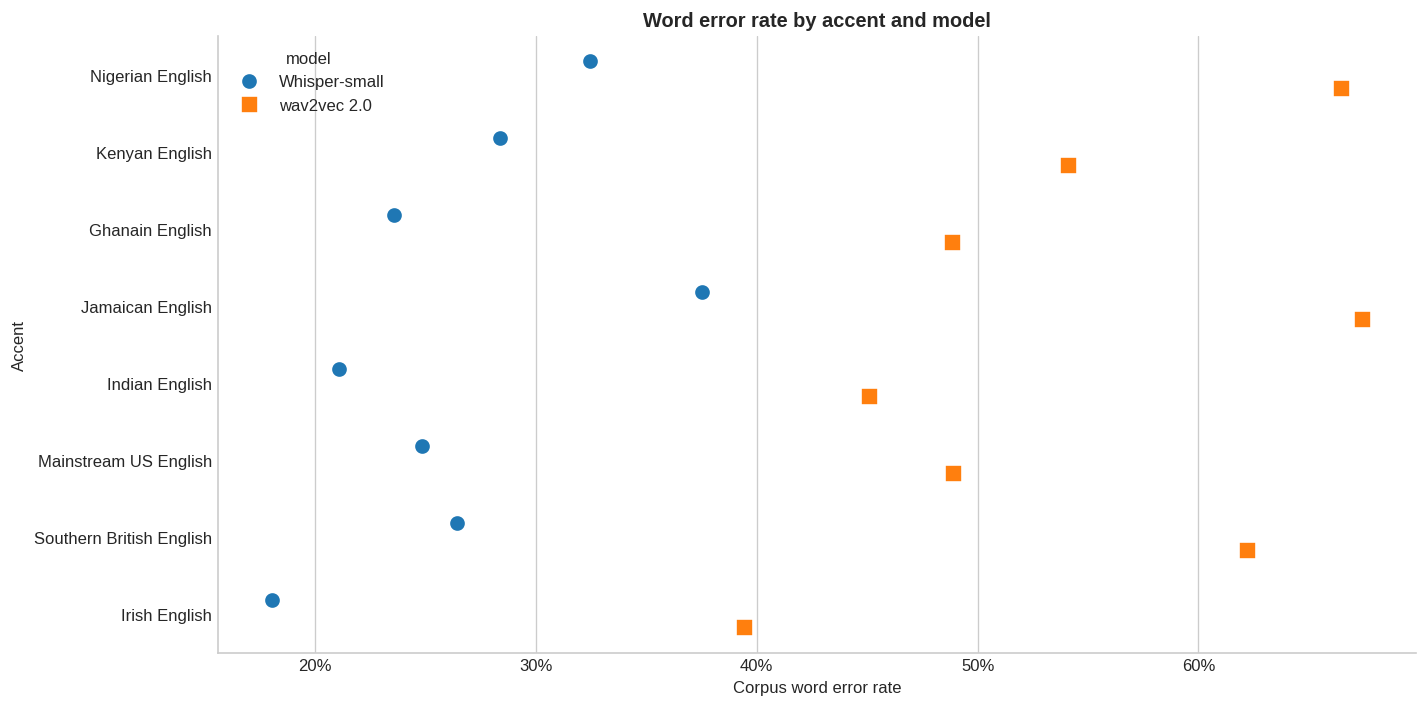

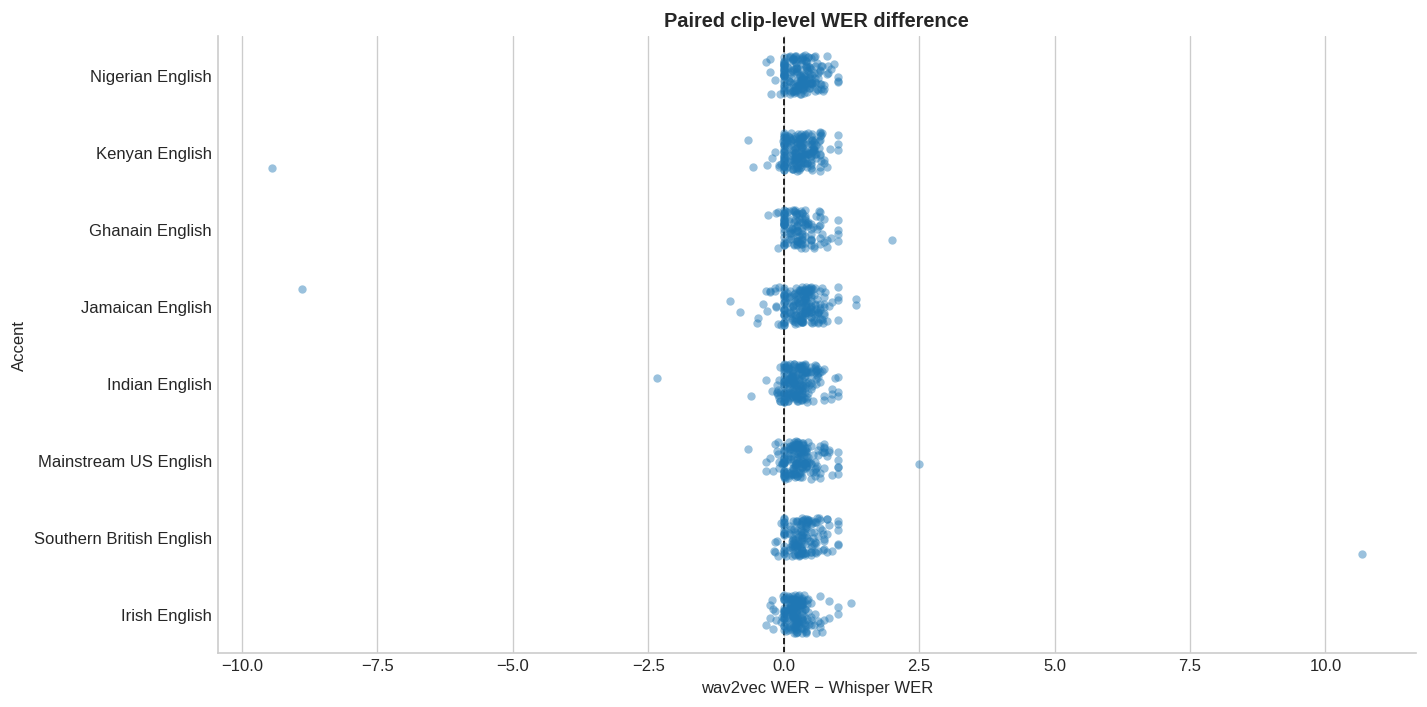

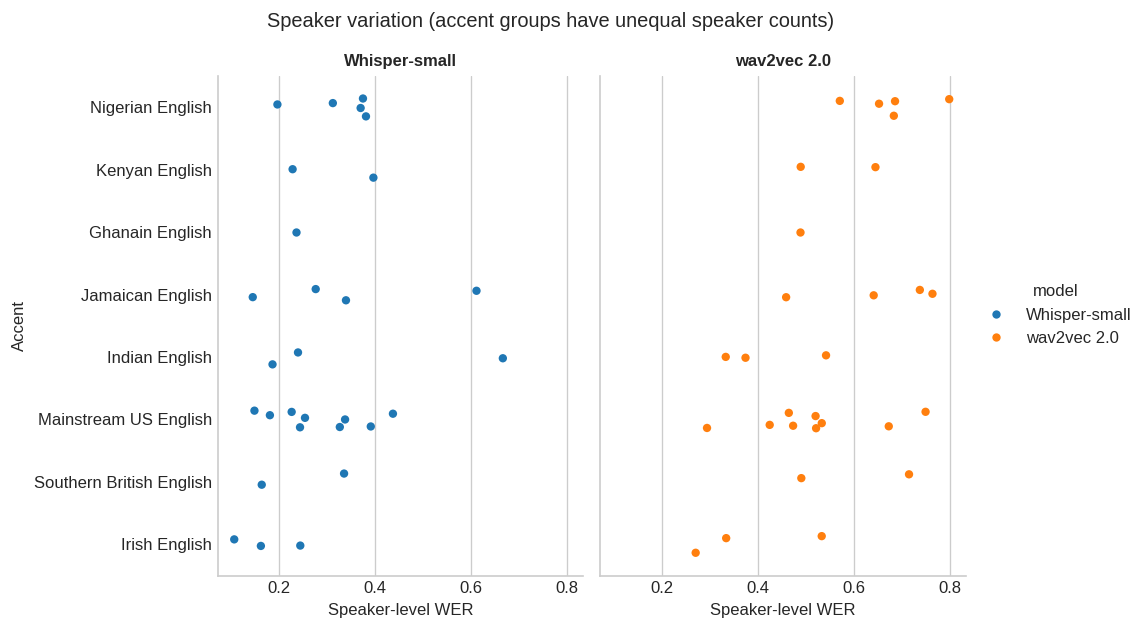

,model,accent,speakers,clips
0,Whisper-small,Ghanain English,1,131
1,Whisper-small,Indian English,3,198
2,Whisper-small,Irish English,3,181
3,Whisper-small,Jamaican English,4,194
4,Whisper-small,Kenyan English,2,196
5,Whisper-small,Mainstream US English,9,179
6,Whisper-small,Nigerian English,5,190
7,Whisper-small,Southern British English,2,153
8,wav2vec 2.0,Ghanain English,1,131
9,wav2vec 2.0,Indian English,3,198


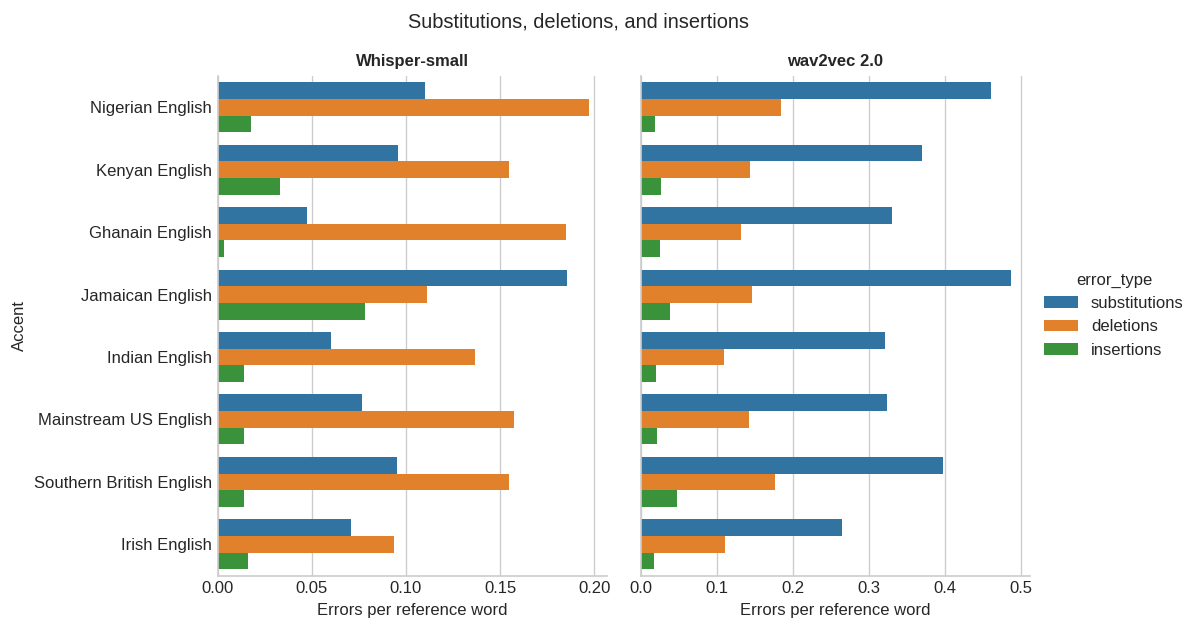

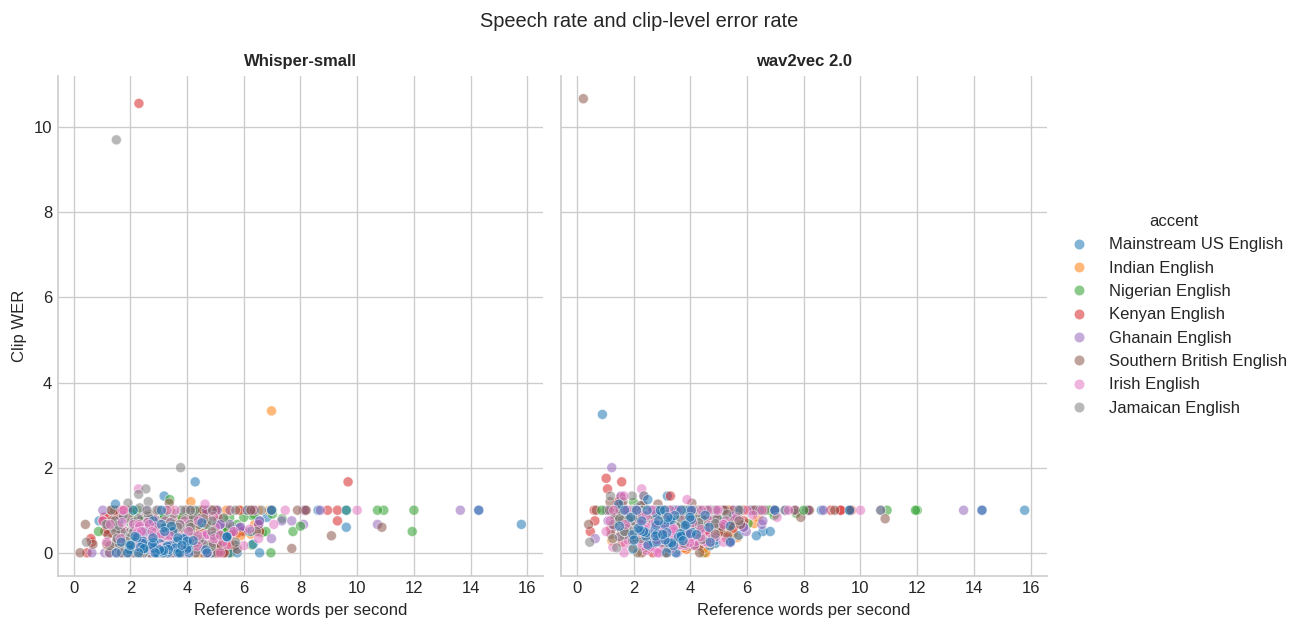

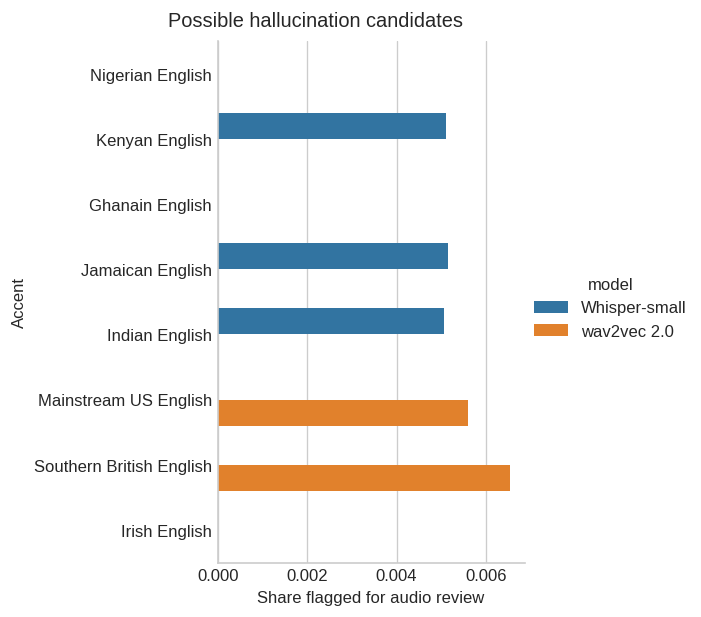

,model,accent,speaker,reference,hypothesis
67,wav2vec 2.0,Mainstream US English,EDACC-C20-B,<DTMF> IS OKAY UH,ET THAT TAT I WILL BEOFTEOTHER ME O GIEN O TE ...
100,Whisper-small,Indian English,EDACC-C05-B,WHAT ABOUT YOU,"I'm sorry, I was just going to say that."
722,Whisper-small,Kenyan English,EDACC-C35-A,REALLY NO NO NO NO TAKEBACKS NO TAKEBACKS <LAUGH>,"No, no, no, no, no, no, no, no, no, no, no, no..."
1913,wav2vec 2.0,Southern British English,EDACC-C42-B,IT'S GETTING VERY LOUD NOW,SALY STADING BY WA I HAV SUCH A FESS AN EDPEND...
2542,Whisper-small,Jamaican English,EDACC-C52-B,LIKE I KNOW I WATCH UM UH <DTMF> UH I,"But I know I watch um, I, I, I, I, I, I, I, I,..."


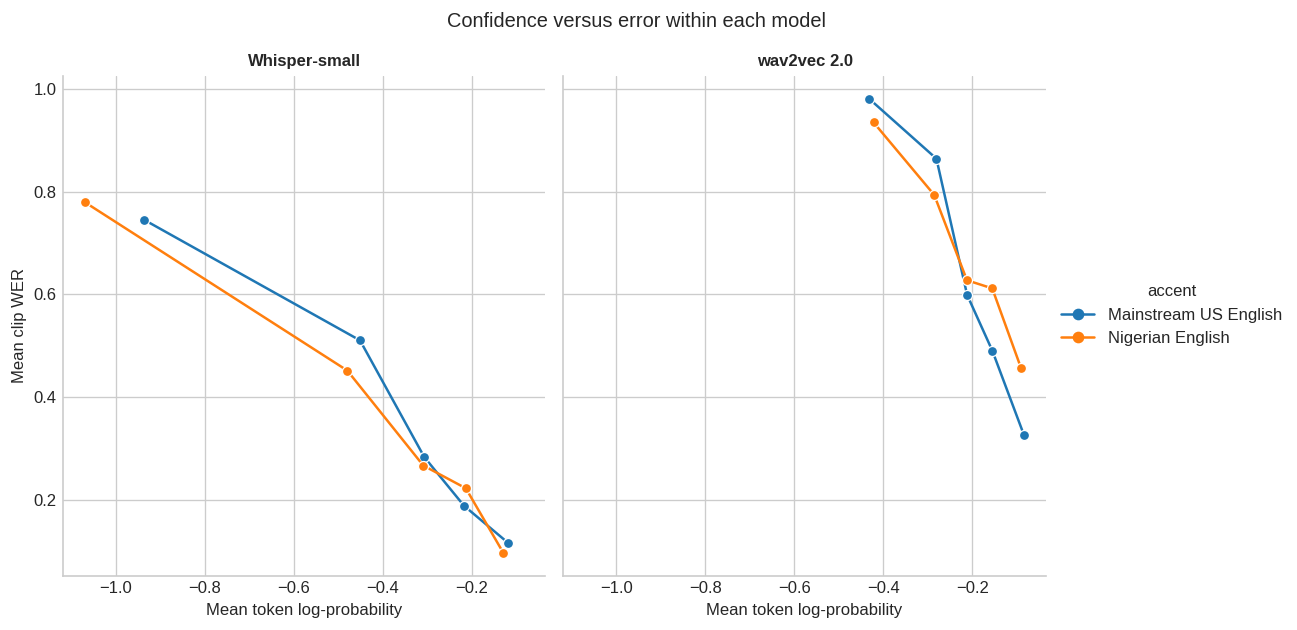

In [9]:
# Plot 1: WER by accent and model.
plt.figure(figsize=(12, 6))
sns.pointplot(
    data=summary,
    x="wer",
    y="accent",
    hue="model",
    order=ACCENTS,
    dodge=0.35,
    markers=["o", "s"],
    linestyles="none",
)
plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value:.0%}")
)
plt.title("Word error rate by accent and model")
plt.xlabel("Corpus word error rate")
plt.ylabel("Accent")
plt.tight_layout()
plt.show()


# Plot 2: Paired clip-level difference.
# Positive values mean wav2vec had higher WER on that same clip.
paired = long_df.pivot(
    index=["row", "accent"],
    columns="model",
    values="wer",
).reset_index()
paired["difference_wav2vec_minus_whisper"] = (
    paired["wav2vec 2.0"] - paired["Whisper-small"]
)

plt.figure(figsize=(12, 6))
sns.stripplot(
    data=paired,
    x="difference_wav2vec_minus_whisper",
    y="accent",
    order=ACCENTS,
    jitter=0.25,
    alpha=0.45,
)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.title("Paired clip-level WER difference")
plt.xlabel("wav2vec WER − Whisper WER")
plt.ylabel("Accent")
plt.tight_layout()
plt.show()


# Plot 3: Speaker-level WER. Each point represents a speaker.
speaker_summary = (
    long_df.groupby(["model", "accent", "speaker"], as_index=False)
    .agg(
        clips=("row", "nunique"),
        ref_words=("ref_words", "sum"),
        errors=("error_count", "sum"),
    )
)
speaker_summary["wer"] = (
    speaker_summary["errors"] / speaker_summary["ref_words"]
)

g = sns.catplot(
    data=speaker_summary,
    x="wer",
    y="accent",
    hue="model",
    col="model",
    kind="strip",
    order=ACCENTS,
    jitter=0.15,
    height=5,
    aspect=0.85,
    sharex=True,
)
g.set_axis_labels("Speaker-level WER", "Accent")
g.set_titles("{col_name}")
g.fig.suptitle(
    "Speaker variation (accent groups have unequal speaker counts)",
    y=1.04,
)
plt.show()

display(
    speaker_summary.groupby(["model", "accent"], as_index=False)
    .agg(speakers=("speaker", "nunique"), clips=("clips", "sum"))
)


# Plot 4: Error composition per reference word.
error_mix = summary.melt(
    id_vars=["model", "accent", "ref_words"],
    value_vars=["substitutions", "deletions", "insertions"],
    var_name="error_type",
    value_name="count",
)
error_mix["rate"] = error_mix["count"] / error_mix["ref_words"]

g = sns.catplot(
    data=error_mix,
    x="rate",
    y="accent",
    hue="error_type",
    col="model",
    kind="bar",
    order=ACCENTS,
    height=5,
    aspect=0.9,
    sharex=False,
)
g.set_axis_labels("Errors per reference word", "Accent")
g.set_titles("{col_name}")
g.fig.suptitle("Substitutions, deletions, and insertions", y=1.04)
plt.show()


# Plot 5: Speech rate versus clip WER, faceted by model.
g = sns.relplot(
    data=long_df,
    x="words_per_s",
    y="wer",
    hue="accent",
    col="model",
    kind="scatter",
    alpha=0.55,
    height=5,
    aspect=0.9,
)
g.set_axis_labels("Reference words per second", "Clip WER")
g.set_titles("{col_name}")
g.fig.suptitle("Speech rate and clip-level error rate", y=1.04)
plt.show()


# Plot 6: Possible hallucination candidates for manual audio review.
# This is a flag for review, not proof that the added words were unspoken.
long_df["hallucination_candidate"] = (
    (long_df["length_ratio"] > 2)
    & ((long_df["hyp_words"] - long_df["ref_words"]) >= 5)
)

candidate_summary = (
    long_df.groupby(["model", "accent"], as_index=False)
    .agg(
        clips=("row", "nunique"),
        candidates=("hallucination_candidate", "sum"),
    )
)
candidate_summary["candidate_rate"] = (
    candidate_summary["candidates"] / candidate_summary["clips"]
)

g = sns.catplot(
    data=candidate_summary,
    x="candidate_rate",
    y="accent",
    hue="model",
    kind="bar",
    order=ACCENTS,
    height=5,
    aspect=1,
)
g.set_axis_labels("Share flagged for audio review", "Accent")
g.fig.suptitle("Possible hallucination candidates", y=1.02)
plt.show()

display(
    long_df[long_df["hallucination_candidate"]][
        ["model", "accent", "speaker", "reference", "hypothesis"]
    ].head(12)
)


# Plot 7: Confidence versus error, with confidence binned separately per model.
long_df["confidence_bin"] = np.nan

for model_name, group in long_df.groupby("model"):
    valid = group["confidence"].notna()
    if valid.sum() >= 5:
        ranks = group.loc[valid, "confidence"].rank(method="first")
        long_df.loc[group.index[valid], "confidence_bin"] = pd.qcut(
            ranks,
            q=5,
            labels=False,
        )

calibration = (
    long_df.dropna(subset=["confidence_bin"])
    .groupby(["model", "accent", "confidence_bin"], as_index=False)
    .agg(
        mean_confidence=("confidence", "mean"),
        mean_wer=("wer", "mean"),
        clips=("row", "nunique"),
    )
)

g = sns.relplot(
    data=calibration[calibration["accent"].isin([FOCUS, BASELINE])],
    x="mean_confidence",
    y="mean_wer",
    hue="accent",
    col="model",
    kind="line",
    marker="o",
    height=5,
    aspect=0.9,
)
g.set_axis_labels("Mean token log-probability", "Mean clip WER")
g.set_titles("{col_name}")
g.fig.suptitle(
    "Confidence versus error within each model",
    y=1.04,
)
plt.show()

In [10]:
# Keep model outputs and derived metrics together for later analysis.
long_df.to_csv("edacc_phase1_two_model_analysis.csv", index=False)
print("Saved paired analysis to edacc_phase1_two_model_analysis.csv")

Saved paired analysis to edacc_phase1_two_model_analysis.csv


In [11]:
%pip -q install umap-learn scikit-learn

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


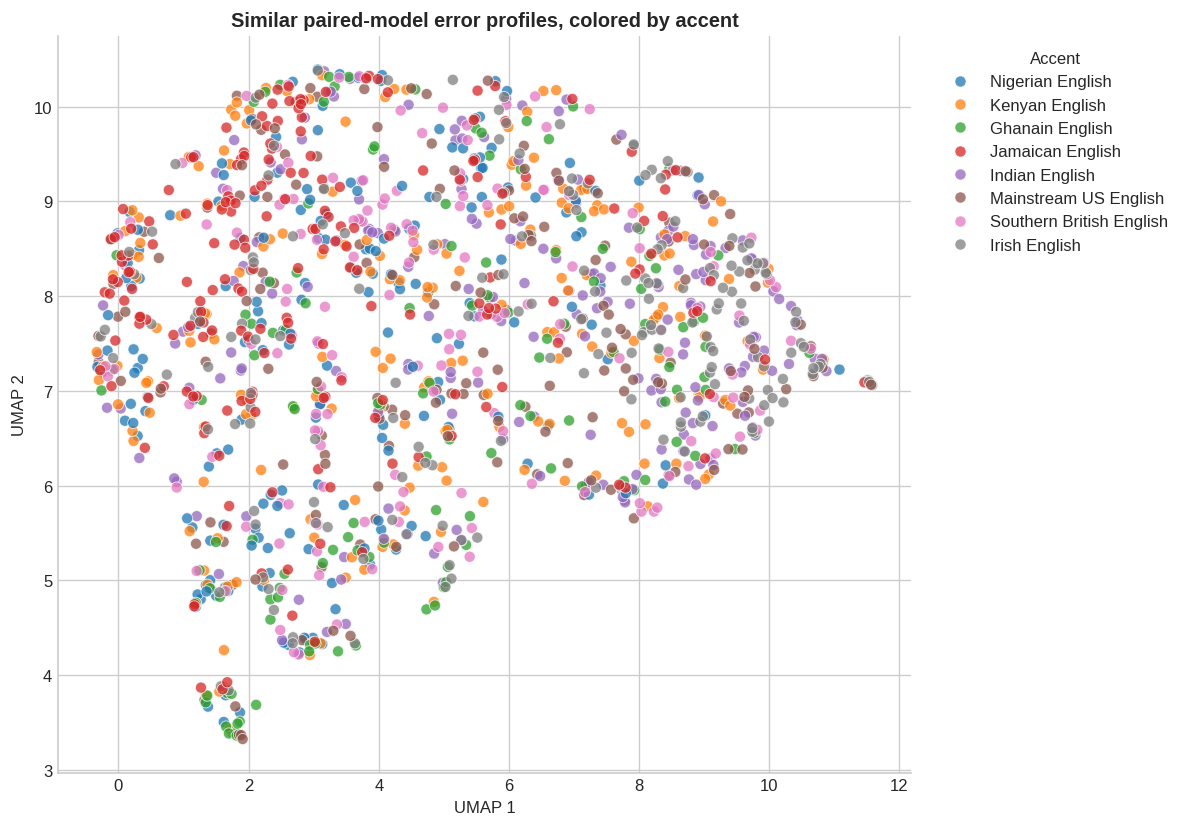

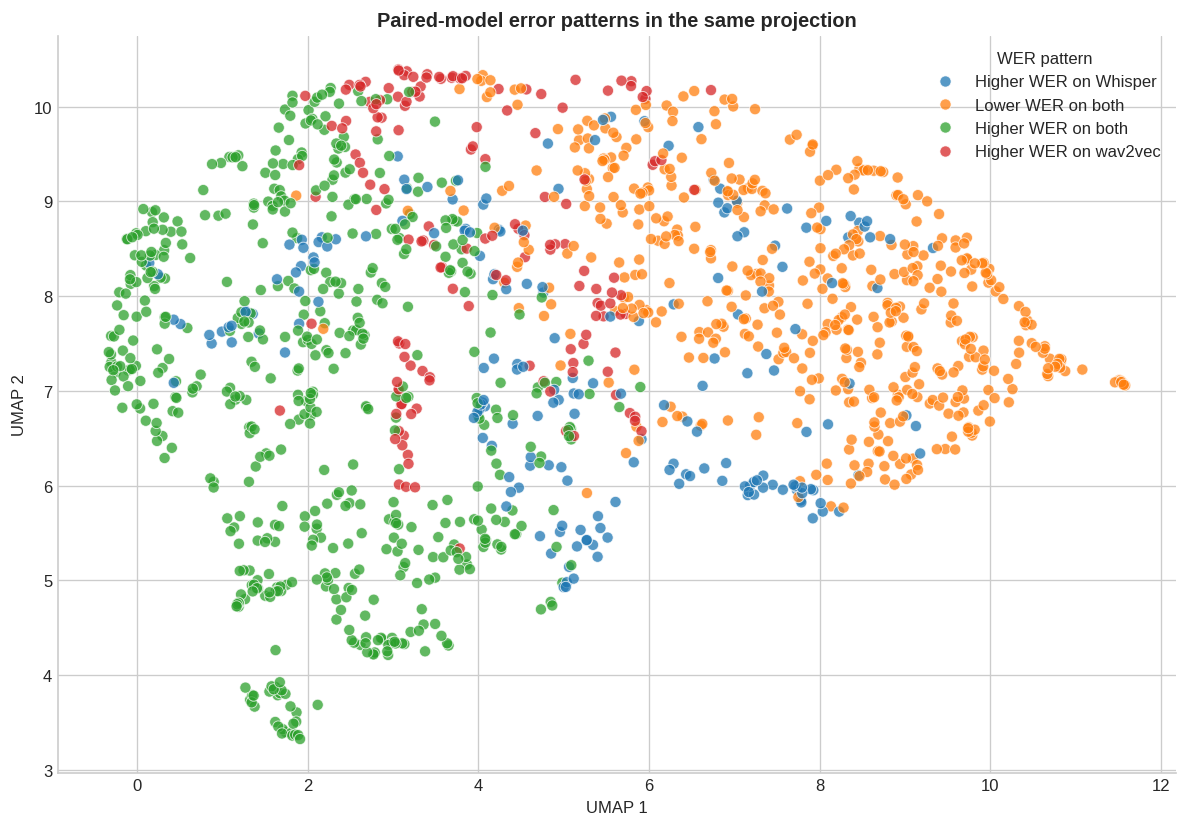

Correlation between the models' clip-level WER: 0.282425085867068


In [12]:
# 9. Do clips with similar error patterns appear near each other?

from sklearn.preprocessing import StandardScaler
import umap

# Build error rates so clips with longer references don't automatically dominate.
long_df["sub_rate"] = long_df["substitutions"] / long_df["ref_words"]
long_df["del_rate"] = long_df["deletions"] / long_df["ref_words"]
long_df["ins_rate"] = long_df["insertions"] / long_df["ref_words"]

# Confidence scales differ between models. Standardize within each model
# so the projection uses relative confidence, not raw-score comparisons.
long_df["confidence_z"] = long_df.groupby("model")["confidence"].transform(
    lambda scores: (
        (scores - scores.mean()) / scores.std(ddof=0)
        if scores.std(ddof=0) > 0 else 0
    )
)

# Each clip becomes one feature vector containing both models' error patterns.
features = ["sub_rate", "del_rate", "ins_rate", "confidence_z"]

wide = long_df.pivot(
    index=["row", "accent", "speaker"],
    columns="model",
    values=features,
)

wide.columns = [
    f"{feature}_{model.replace(' ', '_')}"
    for feature, model in wide.columns
]
wide = wide.reset_index()

feature_cols = [column for column in wide.columns if column not in
                ["row", "accent", "speaker"]]

# Fill any missing confidence values with that feature's median,
# then standardize feature scales before projecting.
X = wide[feature_cols].replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())
X_scaled = StandardScaler().fit_transform(X)

# UMAP summarizes similarity in the observed output-feature vectors.
projection = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    metric="euclidean",
    random_state=SEED,
)
coords = projection.fit_transform(X_scaled)

plot_df = wide[["row", "accent", "speaker"]].copy()
plot_df["UMAP 1"] = coords[:, 0]
plot_df["UMAP 2"] = coords[:, 1]

# Plot the same projection colored by accent. Accent is not used to fit UMAP.
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=plot_df,
    x="UMAP 1",
    y="UMAP 2",
    hue="accent",
    hue_order=ACCENTS,
    alpha=0.75,
    s=45,
)
plt.title("Similar paired-model error profiles, colored by accent")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Accent")
plt.tight_layout()
plt.show()

# Also color by whether each model's WER is above or below its own median.
wer_wide = long_df.pivot(
    index="row",
    columns="model",
    values="wer",
)
whisper_high = (
    wer_wide["Whisper-small"] >= wer_wide["Whisper-small"].median()
)
wav2vec_high = (
    wer_wide["wav2vec 2.0"] >= wer_wide["wav2vec 2.0"].median()
)

behavior = np.select(
    [
        whisper_high & wav2vec_high,
        whisper_high & ~wav2vec_high,
        ~whisper_high & wav2vec_high,
    ],
    [
        "Higher WER on both",
        "Higher WER on Whisper",
        "Higher WER on wav2vec",
    ],
    default="Lower WER on both",
)

plot_df["WER pattern"] = plot_df["row"].map(
    dict(zip(wer_wide.index, behavior))
)

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=plot_df,
    x="UMAP 1",
    y="UMAP 2",
    hue="WER pattern",
    alpha=0.75,
    s=45,
)
plt.title("Paired-model error patterns in the same projection")
plt.tight_layout()
plt.show()

# Check whether clip-level WER tends to rise or fall together across models.
print(
    "Correlation between the models' clip-level WER:",
    wer_wide["Whisper-small"].corr(wer_wide["wav2vec 2.0"]),
)

In [13]:
%pip -q install plotly

In [20]:
import plotly.express as px
import ipywidgets as widgets
from IPython.display import display
import numpy as np

plot_df = long_df.copy()

# Compare each clip's WER with that model's median.
model_medians = plot_df.groupby("model")["wer"].transform("median")
plot_df["WER pattern"] = np.where(
    plot_df["wer"] > model_medians,
    "Above that model's median",
    "At or below that model's median",
)

model_menu = widgets.Dropdown(
    options=["Both models"] + sorted(plot_df["model"].dropna().unique().tolist()),
    value="Both models",
    description="Model:",
)
accent_menu = widgets.Dropdown(
    options=["All accents"] + sorted(plot_df["accent"].dropna().unique().tolist()),
    value="All accents",
    description="Accent:",
)
pattern_menu = widgets.Dropdown(
    options=["All patterns"] + sorted(plot_df["WER pattern"].unique().tolist()),
    value="All patterns",
    description="WER pattern:",
)

chart = widgets.Output()

def draw_plot(*_):
    chart.clear_output(wait=True)

    view = plot_df.copy()
    if model_menu.value != "Both models":
        view = view[view["model"] == model_menu.value]
    if accent_menu.value != "All accents":
        view = view[view["accent"] == accent_menu.value]
    if pattern_menu.value != "All patterns":
        view = view[view["WER pattern"] == pattern_menu.value]

    with chart:
        if view.empty:
            print("No clips match these selections.")
            return

        fig = px.scatter(
            view,
            x="wer",
            y="confidence_z",
            color="WER pattern",
            symbol="model",
            hover_data=["row", "accent", "speaker", "model"],
            title="Clip-level WER and within-model confidence",
            labels={
                "wer": "Word error rate",
                "confidence_z": "Confidence (standardized within model)",
            },
        )
        display(fig)

model_menu.observe(draw_plot, names="value")
accent_menu.observe(draw_plot, names="value")
pattern_menu.observe(draw_plot, names="value")

display(widgets.HBox([model_menu, accent_menu, pattern_menu]))
display(chart)
draw_plot()

Output()

In [19]:
from google.colab import output
output.enable_custom_widget_manager()

In [21]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import plotly.express as px
import ipywidgets as widgets
from IPython.display import display
import numpy as np
import pandas as pd

# Keep only the columns needed for this projection.
error_columns = ["wer", "sub_rate", "del_rate", "ins_rate"]

# Standardize each error metric within each model.
# This lets us compare relative error patterns across the two models.
error_scaled = long_df[["row", "model"] + error_columns].copy()

for column in error_columns:
    error_scaled[column] = error_scaled.groupby("model")[column].transform(
        lambda values: (
            (values - values.mean()) / values.std(ddof=0)
            if values.std(ddof=0) > 0 else 0
        )
    )

# Make one row per clip, with separate feature columns for each model.
error_wide = error_scaled.pivot(
    index="row",
    columns="model",
    values=error_columns,
)

# Flatten the two-level column names, e.g. wer_Whisper-small.
error_wide.columns = [
    f"{metric}_{model}" for metric, model in error_wide.columns
]
error_wide = error_wide.reset_index()

# Attach clip metadata once per row.
clip_meta = (
    long_df[["row", "accent", "speaker", "reference", "duration_s"]]
    .drop_duplicates("row")
)
error_wide = error_wide.merge(clip_meta, on="row", how="left")

# Keep clips with complete results from both models.
feature_cols = [
    column for column in error_wide.columns
    if any(column.startswith(metric + "_") for metric in error_columns)
]
error_wide = error_wide.dropna(subset=feature_cols).copy()

# Project the paired model error features to two PCA dimensions.
error_pca = PCA(n_components=2, random_state=42)
error_coords = error_pca.fit_transform(
    StandardScaler().fit_transform(error_wide[feature_cols])
)
error_wide["PC1"] = error_coords[:, 0]
error_wide["PC2"] = error_coords[:, 1]

print("Error projection variance explained:",
      error_pca.explained_variance_ratio_.round(3))
print("Clips included:", len(error_wide))

Error projection variance explained: [0.323 0.206]
Clips included: 1422


In [22]:
error_wide["WER pattern"] = np.where(
    error_wide[[c for c in feature_cols if c.startswith("wer_")]].abs().mean(axis=1)
        > error_wide[[c for c in feature_cols if c.startswith("wer_")]].abs()
          .mean(axis=1).median(),
    "Higher relative WER",
    "Lower relative WER",
)

accent_menu = widgets.Dropdown(
    options=["All accents"] + sorted(error_wide["accent"].dropna().unique()),
    value="All accents",
    description="Accent:",
)
color_menu = widgets.Dropdown(
    options=["accent", "speaker", "WER pattern"],
    value="accent",
    description="Color by:",
)
error_output = widgets.Output()

def show_error_projection(*_):
    error_output.clear_output(wait=True)

    view = error_wide.copy()
    if accent_menu.value != "All accents":
        view = view[view["accent"] == accent_menu.value]

    with error_output:
        if view.empty:
            print("No clips match this accent selection.")
            return

        fig = px.scatter(
            view,
            x="PC1",
            y="PC2",
            color=color_menu.value,
            hover_data=["row", "accent", "speaker", "WER pattern"],
            title="PCA projection of paired Whisper and wav2vec error patterns",
            labels={"PC1": "Principal component 1", "PC2": "Principal component 2"},
        )
        display(fig)

accent_menu.observe(show_error_projection, names="value")
color_menu.observe(show_error_projection, names="value")

display(widgets.HBox([accent_menu, color_menu]))
display(error_output)
show_error_projection()

Output()

In [23]:
import librosa

acoustic_rows = []

for row in tqdm(error_wide["row"].astype(int), desc="Extracting audio features"):
    audio_record = ds[int(row)]["audio"]
    audio = load_audio(audio_record)  # Uses your earlier load_audio() helper.
    duration = len(audio) / 16_000

    # Use the matching reference length to estimate speaking rate.
    reference_words = int(
        long_df.loc[long_df["row"] == row, "ref_words"].iloc[0]
    )

    acoustic_rows.append({
        "row": row,
        "audio_duration_s": duration,
        "reference_words_per_s": reference_words / duration if duration else np.nan,
        "rms_energy": float(np.mean(librosa.feature.rms(y=audio))),
        "spectral_centroid": float(
            np.mean(librosa.feature.spectral_centroid(y=audio, sr=16_000))
        ),
        "zero_crossing_rate": float(
            np.mean(librosa.feature.zero_crossing_rate(y=audio))
        ),
    })

acoustic_df = pd.DataFrame(acoustic_rows)
acoustic_wide = error_wide.merge(acoustic_df, on="row", how="inner")

Extracting audio features:   0%|          | 0/1422 [00:00<?, ?it/s]

In [24]:
acoustic_features = [
    "audio_duration_s",
    "reference_words_per_s",
    "rms_energy",
    "spectral_centroid",
    "zero_crossing_rate",
]

acoustic_wide = acoustic_wide.dropna(subset=acoustic_features).copy()

acoustic_pca = PCA(n_components=2, random_state=42)
acoustic_coords = acoustic_pca.fit_transform(
    StandardScaler().fit_transform(acoustic_wide[acoustic_features])
)
acoustic_wide["PC1"] = acoustic_coords[:, 0]
acoustic_wide["PC2"] = acoustic_coords[:, 1]

print("Acoustic projection variance explained:",
      acoustic_pca.explained_variance_ratio_.round(3))
print("Clips included:", len(acoustic_wide))

acoustic_accent_menu = widgets.Dropdown(
    options=["All accents"] + sorted(acoustic_wide["accent"].dropna().unique()),
    value="All accents",
    description="Accent:",
)
acoustic_color_menu = widgets.Dropdown(
    options=["accent", "speaker", "WER pattern"],
    value="accent",
    description="Color by:",
)
acoustic_output = widgets.Output()

def show_acoustic_projection(*_):
    acoustic_output.clear_output(wait=True)

    view = acoustic_wide.copy()
    if acoustic_accent_menu.value != "All accents":
        view = view[view["accent"] == acoustic_accent_menu.value]

    with acoustic_output:
        if view.empty:
            print("No clips match this accent selection.")
            return

        fig = px.scatter(
            view,
            x="PC1",
            y="PC2",
            color=acoustic_color_menu.value,
            hover_data=[
                "row", "accent", "speaker", "WER pattern",
                "audio_duration_s", "reference_words_per_s",
                "rms_energy", "spectral_centroid", "zero_crossing_rate",
            ],
            title="PCA projection of acoustic features",
            labels={"PC1": "Principal component 1", "PC2": "Principal component 2"},
        )
        display(fig)

acoustic_accent_menu.observe(show_acoustic_projection, names="value")
acoustic_color_menu.observe(show_acoustic_projection, names="value")

display(widgets.HBox([acoustic_accent_menu, acoustic_color_menu]))
display(acoustic_output)
show_acoustic_projection()

Acoustic projection variance explained: [0.404 0.295]
Clips included: 1422


Output()

In [25]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [26]:
long_df.to_csv("/content/drive/MyDrive/edacc_asr_results.csv", index=False)

In [27]:
acoustic_df.to_csv("/content/drive/MyDrive/edacc_acoustic_features.csv", index=False)